# 02 - Preprocessing: Pembersihan dan Penggabungan Pima + GDM

Notebook ini membersihkan kedua dataset secara terpisah (mengikuti
konvensi masing-masing), menyelaraskan nama kolom, lalu menggabungkan
keduanya menjadi satu dataset dengan target `DiagnosisType` 3 kelas
berbasis diagnosis asli.


In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

NOTEBOOK_DIR = Path.cwd()
PROJECT_ROOT = NOTEBOOK_DIR.parent if NOTEBOOK_DIR.name == "notebooks" else NOTEBOOK_DIR
sys.path.insert(0, str(PROJECT_ROOT))

from src.data_loader import load_data
from src.preprocessing import ZERO_AS_MISSING_COLUMNS, mark_missing, count_missing, impute_missing_by_class
from src.gdm_loader import (
    load_gdm_data, count_missing_gdm, impute_gdm_missing_by_class, harmonize_gdm, CLASS_COL,
)
from src.merge import build_pima_portion, build_gdm_portion, merge_datasets, SHARED_FEATURES, DIAGNOSIS_LABELS

DATA_PATH = PROJECT_ROOT / "data" / "diabetes.csv"
GDM_PATH = PROJECT_ROOT / "data" / "gdm_dataset.xlsx"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR = PROJECT_ROOT / "models"
MODELS_DIR.mkdir(exist_ok=True)
OUTPUT_DIR = PROJECT_ROOT / "outputs"
OUTPUT_DIR.mkdir(exist_ok=True)

df_pima = load_data(DATA_PATH)
df_gdm = load_gdm_data(GDM_PATH)
print(f"Pima: {df_pima.shape} | GDM: {df_gdm.shape}")


Pima: (768, 9) | GDM: (3525, 17)


## 1. Bersihkan Pima

Identik dengan revisi-revisi sebelumnya: nilai 0 pada lima kolom
fisiologis ditandai `NaN`, lalu diimputasi median per kelas `Outcome`.


In [2]:
df_pima_bersih = impute_missing_by_class(mark_missing(df_pima))
print("Sisa nilai 0 di kolom fisiologis Pima:", int((df_pima_bersih[ZERO_AS_MISSING_COLUMNS] == 0).sum().sum()))


Sisa nilai 0 di kolom fisiologis Pima: 0


## 2. Bersihkan GDM

GDM sudah memakai `NaN` eksplisit (bukan sentinel 0), sehingga tidak
perlu langkah "tandai nilai 0". Hanya `BMI` dan `OGTT` yang punya nilai
hilang di antara lima kolom yang dipakai bersama Pima -- diimputasi
median per kelas `Class Label` (konsisten dengan pendekatan Pima:
imputasi dikelompokkan per label diagnosis ASLI masing-masing dataset,
bukan per `DiagnosisType` gabungan, karena `DiagnosisType` baru ada
setelah penggabungan).


In [3]:
df_gdm_bersih = impute_gdm_missing_by_class(df_gdm)
print("Sisa NaN BMI:", df_gdm_bersih["BMI"].isna().sum(), "| Sisa NaN OGTT:", df_gdm_bersih["OGTT"].isna().sum())


Sisa NaN BMI: 0 | Sisa NaN OGTT: 0


## 3. Harmonisasi Nama Kolom GDM


In [4]:
df_gdm_harmon = harmonize_gdm(df_gdm_bersih)
df_gdm_harmon.head()


   Age  Pregnancies   BMI  BloodPressure  Glucose  Class Label(GDM /Non GDM)
0   22            2  24.0             69    146.0                          0
1   26            2  24.0             63    146.0                          0
2   29            1  24.0             79    146.0                          0
3   28            2  24.0             70    146.0                          0
4   21            2  24.0             65    146.0                          0

## 4. Bangun Label DiagnosisType dan Gabungkan

- Pima: `Outcome=0` -> `Normal`, `Outcome=1` -> `Tipe 2`
- GDM: `Class=0` -> `Normal`, `Class=1` -> `Gestasional`


In [5]:
pima_portion = build_pima_portion(df_pima_bersih)
gdm_portion = build_gdm_portion(df_gdm_harmon)

print("Pima portion:", pima_portion.shape, "| kolom:", list(pima_portion.columns))
print("GDM portion :", gdm_portion.shape, "| kolom:", list(gdm_portion.columns))

gabungan = merge_datasets(pima_portion, gdm_portion)
print()
print(f"Dataset gabungan: {gabungan.shape}")
print()
print("Distribusi DiagnosisType:")
print(gabungan["DiagnosisType"].value_counts().reindex(DIAGNOSIS_LABELS))
print()
print("Distribusi berdasarkan DiagnosisType x SumberData:")
print(pd.crosstab(gabungan["DiagnosisType"], gabungan["SumberData"]))


Pima portion: (768, 7) | kolom: ['Age', 'Pregnancies', 'BMI', 'BloodPressure', 'Glucose', 'DiagnosisType', 'SumberData']
GDM portion : (3525, 7) | kolom: ['Age', 'Pregnancies', 'BMI', 'BloodPressure', 'Glucose', 'DiagnosisType', 'SumberData']

Dataset gabungan: (4293, 7)

Distribusi DiagnosisType:
DiagnosisType
Normal         2653
Tipe 2          268
Gestasional    1372
Name: count, dtype: int64

Distribusi berdasarkan DiagnosisType x SumberData:
SumberData      GDM  Pima
DiagnosisType            
Gestasional    1372     0
Normal         2153   500
Tipe 2            0   268


Perhatikan: `Tipe 2` hanya berasal dari Pima, `Gestasional` hanya dari
GDM -- `SumberData` secara struktural berkorelasi dengan
`DiagnosisType` (bukan perfect predictor, karena `Normal` muncul di
keduanya, tetapi tetap berkorelasi kuat). Ini bagian dari keterbatasan
yang sama dibahas pada `01_EDA` bagian 7, dan dibuktikan dampaknya pada
`04_Evaluation`.


## 5. Visualisasi Distribusi Fitur Gabungan per Kelas


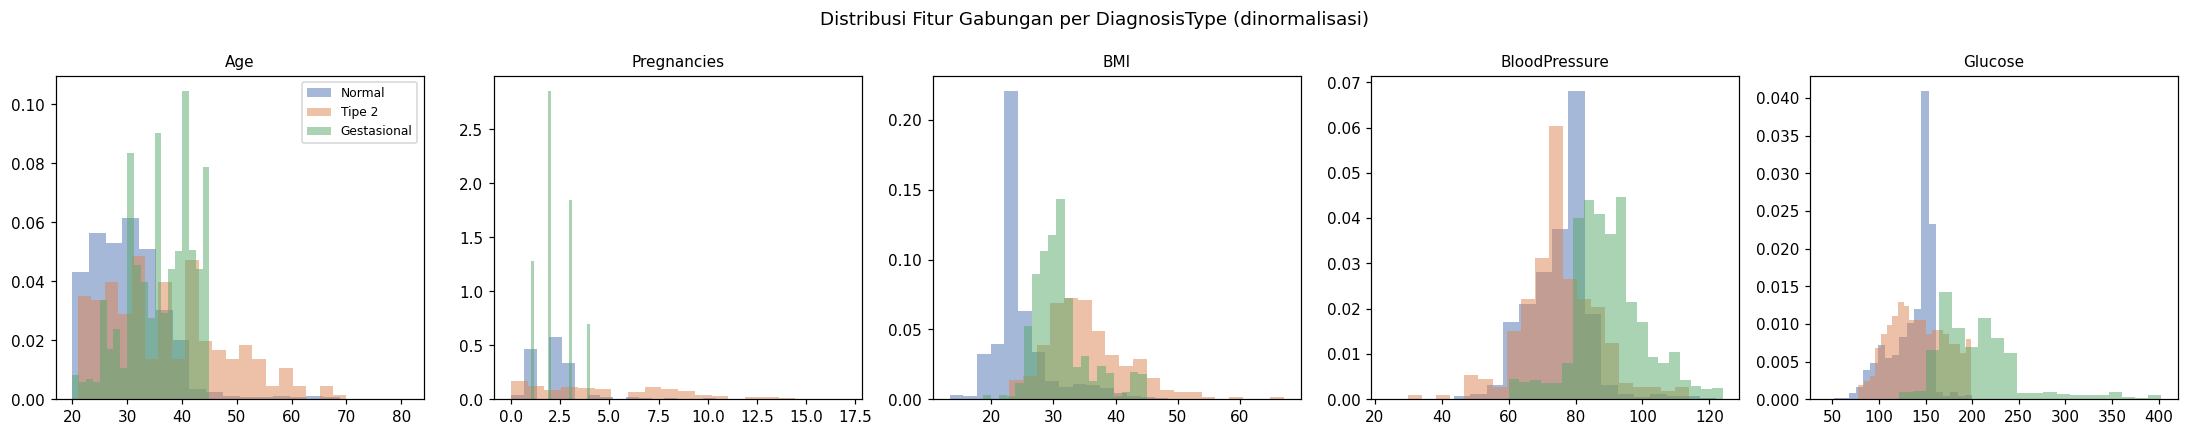

In [6]:
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for ax, kolom in zip(axes, SHARED_FEATURES):
    for kelas, warna in zip(DIAGNOSIS_LABELS, ["#4C72B0", "#DD8452", "#55A868"]):
        data = gabungan.loc[gabungan["DiagnosisType"] == kelas, kolom]
        ax.hist(data, bins=20, alpha=0.5, color=warna, label=kelas, density=True)
    ax.set_title(kolom, fontsize=10)
axes[0].legend(fontsize=8)
fig.suptitle("Distribusi Fitur Gabungan per DiagnosisType (dinormalisasi)")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "preprocessing_merged_feature_distributions.png", dpi=150, bbox_inches="tight")
plt.show()


`BMI` menunjukkan pemisahan yang mencurigakan rapi antara kelompok
Pima (`Normal`, `Tipe 2`) vs GDM (`Gestasional`) -- konsisten dengan
temuan `01_EDA` bahwa ini sebagian mencerminkan perbedaan sumber data,
bukan murni tipe diabetes.


## 6. Simpan Dataset Gabungan


In [7]:
output_path = PROCESSED_DIR / "merged_diagnosis.csv"
gabungan.to_csv(output_path, index=False)
print(f"Tersimpan: {output_path} ({gabungan.shape[0]} baris, {gabungan.shape[1]} kolom)")


Tersimpan: /home/claude/build/diabetes-risk-gnb/data/processed/merged_diagnosis.csv (4293 baris, 7 kolom)


## 7. Median Data Mentah untuk Kebutuhan Deployment (Aplikasi Streamlit)

Sama seperti revisi sebelumnya: median Pima dihitung dari seluruh data
mentah tanpa bergantung pada label, dipakai untuk mengisi nilai yang
tidak diketahui pengguna aplikasi.


In [8]:
import json

df_ditandai = mark_missing(df_pima)
median_keseluruhan = df_ditandai[ZERO_AS_MISSING_COLUMNS].median()

with open(MODELS_DIR / "imputation_medians.json", "w", encoding="utf-8") as f:
    json.dump({k: round(float(v), 2) for k, v in median_keseluruhan.items()}, f, indent=2, ensure_ascii=False)

median_keseluruhan


Glucose          117.0
BloodPressure     72.0
SkinThickness     29.0
Insulin          125.0
BMI               32.3
dtype: float64

**Lanjut ke `03_GaussianNB.ipynb`** untuk pelatihan model Gaussian
Naive Bayes memakai target `DiagnosisType`.
